# Fourier Analysis Demo
Showcase of base experiments to analyse Fourier space of solution

## 0 - Setup

In [20]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN, MerlinTunableSimple
from src.pde     import HeatEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import (
    plot_training_history,
    plot_solution_comparison,
    plot_power_spectrum,
    plot_mode_l2_errors,
    plot_frequency_sweep,
    plot_multi_model_l2_error
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu  |  dtype: torch.float32


## 1 - Frequency Sweep
Train both models on heat equatin over a range of IC frequencies

In [2]:
FREQUENCIES = [0.5, 1.0, 1.5, 2, 2.5, 3, 3.5]
SEEDS = [42, 666, 69, 67, 13]

In [3]:
sweep_results = {"classical": [], "qpinn_weights": []} #"qpinn": [], 
for freq in FREQUENCIES:
    pde = HeatEquation(freq=freq)
    print(f"\n{'='*60}\nfreq = {freq}")
    seed_results = {"classical": [], "qpinn_weights": []}
    for i,seed in enumerate(SEEDS):
#        # --- QPINN ---
#        qpinn = MerlinHeatQPINN().to(device)
#        train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
#        metrics, _, _, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)
#        sweep_results["qpinn"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
#        print(f"  QPINN_SEED_{seed}      rel_l2 = {metrics['rel_l2']:.4e}")

        # --- Classical ---
        classical = ClassicalHeatQPINN().to(device)
        train(model=classical, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
        metrics, _, _, _, _ = evaluate(model=classical, pde=pde, device=device, dtype=dtype)
        seed_results["classical"].append(metrics["rel_l2"])
        
        print(f"  Classical_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")

        # --- QPINN WEIGHTS ---
        qpinn_weights = MerlinTunableSimple().to(device)
        train(model=qpinn_weights, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
        metrics, _, _, _, _ = evaluate(model=qpinn_weights, pde=pde, device=device, dtype=dtype)
        seed_results["qpinn_weights"].append(metrics["rel_l2"])
        print(f"  QPINN WEIGHTS_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")
    
    sweep_results["classical"].append({"frequency": freq, "rel_l2": seed_results["classical"]})
    sweep_results["qpinn_weights"].append({"frequency": freq, "rel_l2": seed_results["qpinn_weights"]})



freq = 0.5
Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 1.1386e+01 | PDE: 1.26e-04 | Cons: 9.34e-02 | IC: 1.11e+00 | BC: 2.43e-01 | Time: 0.0s
Epoch   100/300 | Loss: 1.4018e+00 | PDE: 1.25e-01 | Cons: 1.40e-03 | IC: 1.03e-01 | BC: 2.50e-01 | Time: 0.1s
Epoch   200/300 | Loss: 1.0003e+00 | PDE: 5.73e-02 | Cons: 1.12e-01 | IC: 6.04e-02 | BC: 3.28e-01 | Time: 0.2s
Epoch   300/300 | Loss: 9.3688e-01 | PDE: 2.08e-01 | Cons: 3.91e-01 | IC: 3.36e-02 | BC: 3.55e-01 | Time: 0.4s

Done — 0.4s total
Evaluating on 60×60 grid …
  Relative L2 : 3.2290e-01
  MAE         : 1.3321e-01
  Max abs err : 7.6218e-01
  RMSE        : 2.0118e-01
  Classical_SEED_42   rel_l2 = 3.2290e-01
Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 2.9879e+00 | PDE: 3.29e-08 | Cons: 2.17e-01 | IC: 2.88e-01 | BC: 8.95e-02 | Time: 0.0s
Epoch   100/300 | Loss: 2.7529e-01 | PDE: 5.39e

Saved: figures/fourier_demo/freq_sweep.png


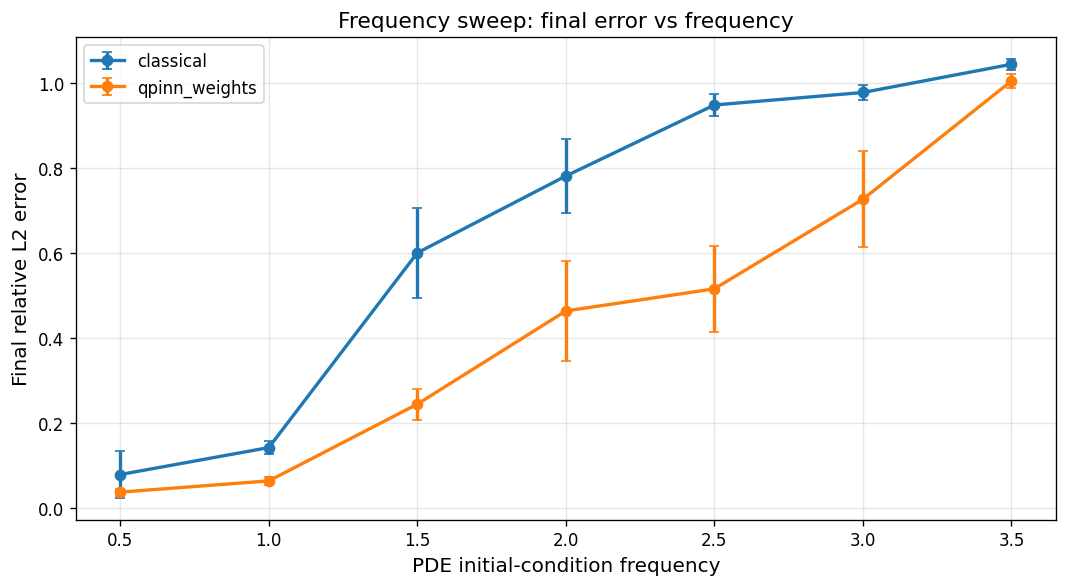

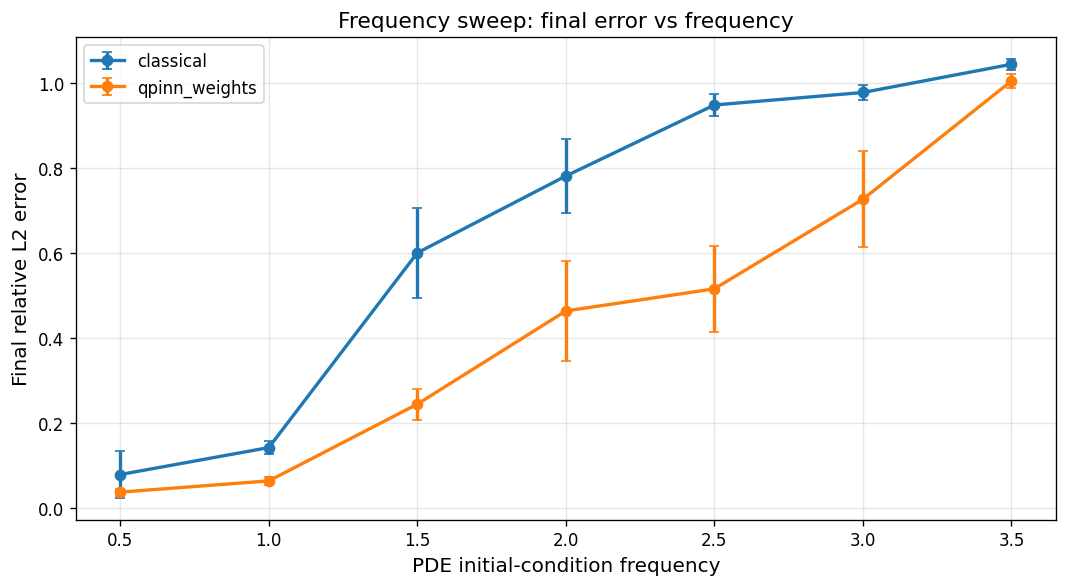

In [25]:
%reload_ext autoreload
plot_frequency_sweep(
    sweep_results,
    save_path = "../figures/fourier_demo/freq_sweep.png",
    show      = True,
)

## 2 - Train both models with same frequency and compare

In [ ]:
FREQUENCY = 3.0

In [ ]:

ref_pde = HeatEquation(freq=FREQUENCY)

# QPINN
qpinn_ref = MerlinHeatQPINN().to(device)
history_q = train(model=qpinn_ref, pde=ref_pde, epochs = 600)

# Classical
classical_ref = ClassicalHeatQPINN().to(device)
history_c = train(model=classical_ref, pde=ref_pde, epochs = 600)

qpinn_weights_ref = MerlinTunableSimple().to(device)
history_qpinn_weights = train(model=qpinn_weights_ref, pde=ref_pde, epochs = 600)

In [ ]:
# Evaluate models
grid_n = 60


_, U_pred_q, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_c, _,      _,      _      = evaluate(model=classical_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_q_w, _,      _,      _      = evaluate(model=qpinn_weights, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

#TODO : figure out here Q error is smaller than C error ??? this doesnt match results from other pipeline

In [ ]:
plot_solution_comparison(U_pred_q,U_true)
plot_solution_comparison(U_pred_c,U_true)
plot_solution_comparison(U_pred_q_w,U_true)


### 2.1 - Compare power spectra

In [ ]:
print("QPINN power spectrum")
plot_power_spectrum(U_pred_q, U_true, save_path="../figures/demo_fourier/power_spectrum_q.png", exclude_0_mode=False)

print("Classical power spectrum")
plot_power_spectrum(U_pred_c, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

### 2.2 Compare per-mode L2 error

In [ ]:
print("QPINN mode errors")
plot_mode_l2_errors(U_pred_q, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q.png")

print("Classical mode errors")
plot_mode_l2_errors(U_pred_c, U_true,
                    save_path="../figures/fourier_demo/l2_error_C.png")

## Compare directly

In [ ]:


plot_multi_model_l2_error(U_true, [U_pred_q, U_pred_c],["Qpinn", "C PINN"])